In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..')
pth_in = os.path.join(pth, 'data', 'modeling', 'landscape')
# pth_out = ...

In [27]:
adata_dev = sc.read_h5ad(os.path.join(pth_in, 'development.h5ad'))
adata_dev = adata_dev[adata_dev.obs.landscape == 'True'].copy()
adata_dev = adata_dev[adata_dev.obs.landscape == 'True'].copy()
adata_dev = adata_dev[~((adata_dev.obs.source == 'GSE162534') &
                        (adata_dev.obs.latent_z < .5))].copy()
adata_dev = adata_dev[~((adata_dev.obs.source == 'GSE229103') &
    (adata_dev[:, 'Pou5f1'].X.toarray() == 0).flatten())].copy()
adata_3ca = sc.read_h5ad(os.path.join(pth_in, 'CCCA.h5ad'))
adata_3ca = adata_3ca[adata_3ca.obs.landscape == 'True'].copy()
adata = sc.concat((adata_dev, adata_3ca), join = 'inner'); adata

AnnData object with n_obs × n_vars = 14731 × 856
    obs: 'celltype', 'sample', 'location', 'batch', 'nCount_RNA', 'nFeature_RNA', 'age', 'source', 'latent_z', 'Early', 'Late', 'X_mesen1', 'X_mesen2', 'landscape'
    obsm: 'X_mesen', 'X_mod'

In [ ]:
names_dict = {
    '../../data/unzip/CCCA/Data_Filbin2018_Brain'           : 'Pediatric H3-K27M Mutant Glioma',
    '../../data/unzip/CCCA/Data_Gojo2020_Brain'             : 'Pediatric Ependymoma',
    '../../data/unzip/CCCA/Data_He2021_Prostate'            : 'Metastatic Prostate Cancer',
    '../../data/unzip/CCCA/Data_Hovestadt2019_Brain'        : 'Medulloblastoma',
    '../../data/unzip/CCCA/Data_Jerby-Arnon2018_Skin'       : 'Melanoma',
    '../../data/unzip/CCCA/Data_Karaayvas2018_Breast'       : 'Triple-Negative Breast Cancer',
    '../../data/unzip/CCCA/Data_Maynard2020_Lung'           : 'Metastatic Non-Small Cell Lung Cancer',
    '../../data/unzip/CCCA/Data_Neftel2019_Brain/SmartSeq2' : 'Glioblastoma',
    '../../data/unzip/CCCA/Data_Puram2017_Head-and-Neck'    : 'Head and Neck Squamous Cell Carcinoma',
    '../../data/unzip/CCCA/Data_Tirosh2016_Brain'           : 'IDH-Mutant Oligodendroglioma',
    '../../data/unzip/CCCA/Data_Venteicher2017_Brain'       : 'IDH-Mutant Astrocytoma',
    'GSE162534'                                             : 'Primitive Streak',
    'GSE229103'                                             : 'NMP',
    'rRNAModifications'                                     : 'CNCC'}

In [ ]:
df = (adata.obs
      .groupby('source', observed = True)
      .Early.quantile(.5)
      .sort_values(ascending = False))

/tmp/ipykernel_3143380/1684514262.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels([names_dict[ix] for ix in df.index], rotation = 90)


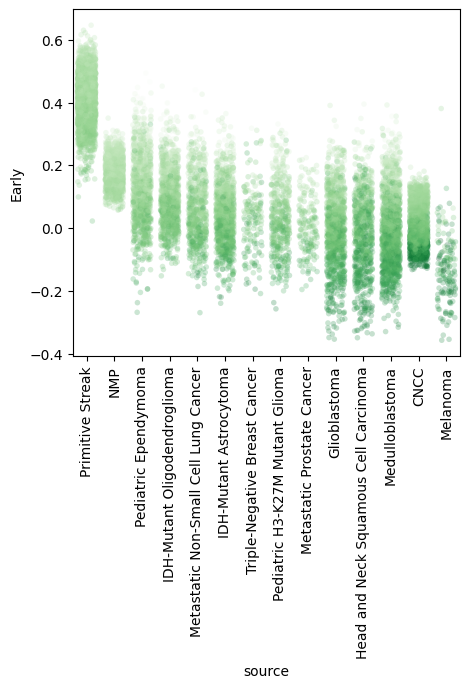

In [35]:
import seaborn as sns

# module stripplot -> dendrogram
fig, ax = plt.subplots(1, 1, figsize = (5, 4.5))
sns.stripplot(data = adata.obs,
              x = 'source',
              y = 'Early',
              hue = 'Late',
              order = df.index,
              palette = 'Greens',
              s = 4, alpha = .25,
              jitter = .33,
              legend = False,
              ax = ax)

plt.gca().set_xticklabels([names_dict[ix] for ix in df.index], rotation = 90)

# ax.set_xticks([]); ax.set_xlabel('')
# xlim = ax.get_xlim()
# ax.set_xlim(xlim[0] - .1, xlim[1] + .1)
# ax.set_ylim(-.2, .7)
# ax.set_ylabel('Early Signature (AU)', size = 10.5)
# for sp in ('top', 'right', 'bottom'):
#     ax.spines[sp].set_visible(False)

plt.show()